In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.utils import gen_batches

from MnistModel import MNISTModel, MNISTConvModel
from nn.loss.crossentropyloss import cross_entropy
from nn.optim.SGD import SGD
from nn.tensor import Tensor
from nn.utils import visualize_computation_graph

In [3]:
mnist = fetch_openml("mnist_784", version=1, as_frame=False)

x = mnist.data
y = mnist.target

In [4]:
x_train_all, y_train_all = x[:60000], y[:60000]
x_test, y_test = x[60000:], y[60000:]

In [5]:
x_train_all = x_train_all.astype(np.float32) / 255.0
x_test = x_test.astype(np.float32) / 255.0
y_train_all = y_train_all.astype(np.int64)
y_test = y_test.astype(np.int64)

In [6]:
x_train, x_validation, y_train, y_validation = train_test_split(x_train_all, y_train_all, test_size=0.1, random_state=42, shuffle=True)

In [7]:
print(f"Training examples: {len(x_train)}")
print(f"Validation examples: {len(y_validation)}")
print(f"Test examples: {len(x_test)}")

Training examples: 54000
Validation examples: 6000
Test examples: 10000


In [8]:
model = MNISTConvModel()
optimizer = SGD(model.parameters(), lr=0.01)

In [9]:
epochs = 1
batch_size = 64

In [ ]:
training_loss, validation_loss = [], []

for epoch in range(epochs): 
    epoch_loss = 0
    training_examples = 0
    for batch_idx in gen_batches(len(x_train), batch_size=batch_size): 
        batch_x = Tensor(x_train[batch_idx], requires_grad=True)
        batch_y = Tensor(y_train[batch_idx], requires_grad = True)

        logits = model(batch_x)
        loss = cross_entropy(logits, batch_y)
        loss.zero_grad()
        loss.backward()
        optimizer.step()

        count = batch_idx.stop - batch_idx.start
        epoch_loss += float(loss.data) * count
        training_examples += count
    training_loss.append(epoch_loss / training_examples)

    epoch_val_loss = 0.0
    val_examples = 0

    for val_batch_idx in gen_batches(len(x_validation), batch_size = batch_size): 
        val_batch_x = Tensor(x_validation[val_batch_idx], requires_grad=False)
        val_batch_y = Tensor(y_validation[val_batch_idx], requires_grad=False)
        val_logits = model(val_batch_x)
        val_loss = cross_entropy(val_logits, val_batch_y)
        val_count = val_batch_idx.stop - val_batch_idx.start
        epoch_val_loss += float(val_loss.data) * val_count
        val_examples += val_count
    validation_loss.append(epoch_val_loss / val_examples)

    print("Epoch %2d/%2d ==> Training Loss: %4f and Validation Loss: %4f" % (epoch, epochs, training_loss[-1], validation_loss[-1]))
    

In [21]:
def visualize(): 
    v_x, v_y = Tensor(x_train[:batch_size], requires_grad = True), Tensor(y_train[:batch_size], requires_grad = True)
    logits = model(v_x)
    loss = cross_entropy(logits, v_y)
    return visualize_computation_graph(loss, "computation_graph.png")

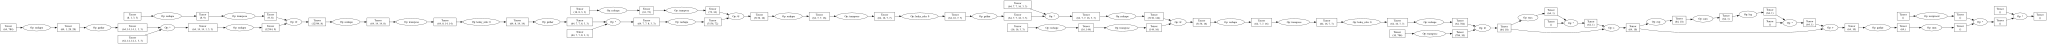

In [22]:
visualize()

In [ ]:
X = Tensor(np.random.randn(2, 8, 16), requires_grad=True)

W_q = Tensor(np.random.randn(16, 16), requires_grad=True)
W_k = Tensor(np.random.randn(16, 16), requires_grad=True)
W_v = Tensor(np.random.randn(16, 16), requires_grad=True)
W_o = Tensor(np.random.randn(16, 16), requires_grad=True)

W1 = Tensor(np.random.randn(16, 32), requires_grad=True)
W2 = Tensor(np.random.randn(32, 16), requires_grad=True)

Q = X @ W_q
K = X @ W_k
V = X @ W_v

scale = Tensor(16.0 ** 0.5, requires_grad=False)
scores = (Q @ K.transpose(0, 2, 1)) / scale

scores_max = scores.max(axis=-1, keepdims=True)
exp_scores = (scores - scores_max).exp()
attn_weights = exp_scores / exp_scores.sum(axis=-1, keepdims=True)

attn_out = (attn_weights @ V) @ W_o

norm1_in = X + attn_out
mean1 = norm1_in.mean(axis=-1, keepdims=True)
var1 = ((norm1_in - mean1) * (norm1_in - mean1)).mean(axis=-1, keepdims=True)
std1 = (var1 + Tensor(1e-5, requires_grad=False)) ** 0.5  # or (var1 + eps)**0.5
norm1_out = (norm1_in - mean1) / std1

hidden = (norm1_out @ W1).leaky_relu()
mlp_out = hidden @ W2

out = norm1_out + mlp_out
loss = out.sum()

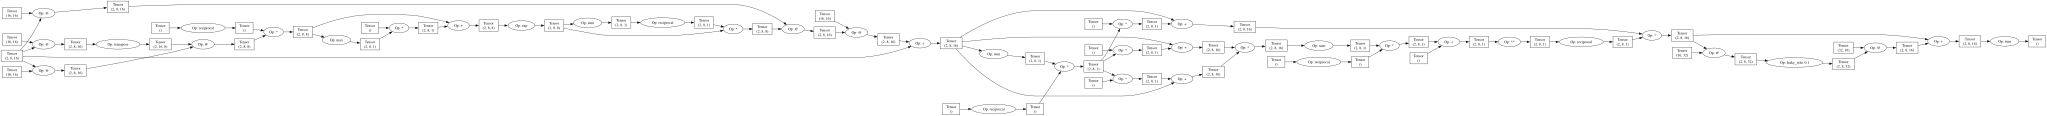

In [18]:
visualize_computation_graph(loss, "transformer_block.png")

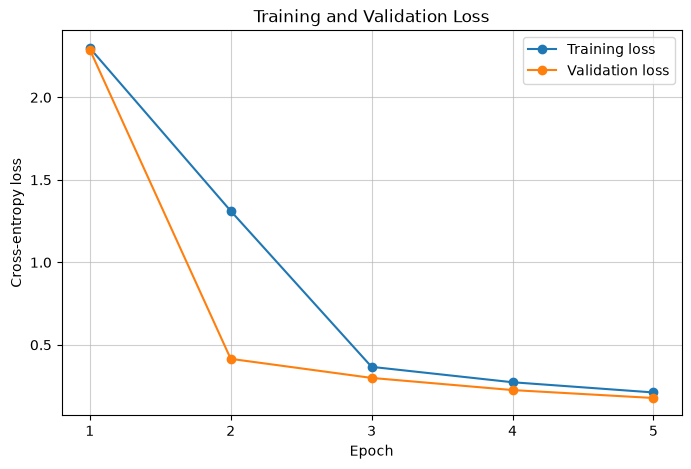

In [10]:
plt.figure(figsize=(8, 5))
epoch_numbers = range(1, epochs + 1)
plt.plot(epoch_numbers, training_loss, marker="o", label="Training loss")
plt.plot(epoch_numbers, validation_loss, marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training and Validation Loss")
plt.xticks(list(epoch_numbers))
plt.grid(True, alpha=0.6)
plt.legend()
plt.show()

In [11]:
test_loss_sum = 0.0
test_examples = 0

for test_batch_idx in gen_batches(len(x_test), batch_size=batch_size):
    x_batch = Tensor(x_test[test_batch_idx], requires_grad=False)
    y_batch = Tensor(y_test[test_batch_idx], requires_grad=False)
    test_logits = model(x_batch)

    count = test_batch_idx.stop - test_batch_idx.start
    test_loss_sum += float(cross_entropy(test_logits, y_batch).data) * count
    test_examples += count

print(f"Test loss: {test_loss_sum / test_examples:.4f}")

Test loss: 0.1790


In [12]:
def predict(x, y, start, end):
    start = max(0, min(start, len(y)))
    end = max(start, min(end, len(y)))
    if start == end:
        raise ValueError("The requested image range is empty.")

    images = x[start:end]
    actual = y[start:end].astype(int)
    predictions = np.argmax(model(Tensor(images)).data, axis=1)

    cols = 8
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2.2))
    axes = np.atleast_1d(axes).ravel()

    for index, (image, target, prediction) in enumerate(zip(images, actual, predictions)):
        ax = axes[index]
        ax.imshow(image.reshape(28, 28), cmap="gray")
        ax.axis("off")
        ax.text(
            0.03, 0.97, f"Prediction: {prediction}",
            transform=ax.transAxes, ha="left", va="top",
            color="black", fontsize=8,
            bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 1.5},
        )
        ax.text(
            0.97, 0.97, f"Actual: {target}",
            transform=ax.transAxes, ha="right", va="top",
            color="black", fontsize=8,
            bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 1.5},
        )
        if prediction != target:
            ax.add_patch(
                plt.Rectangle(
                    (0, 0), 1, 1, transform=ax.transAxes,
                    fill=False, edgecolor="red", linewidth=3, clip_on=False,
                )
            )

    for ax in axes[len(images):]:
        ax.axis("off")

    plt.show()


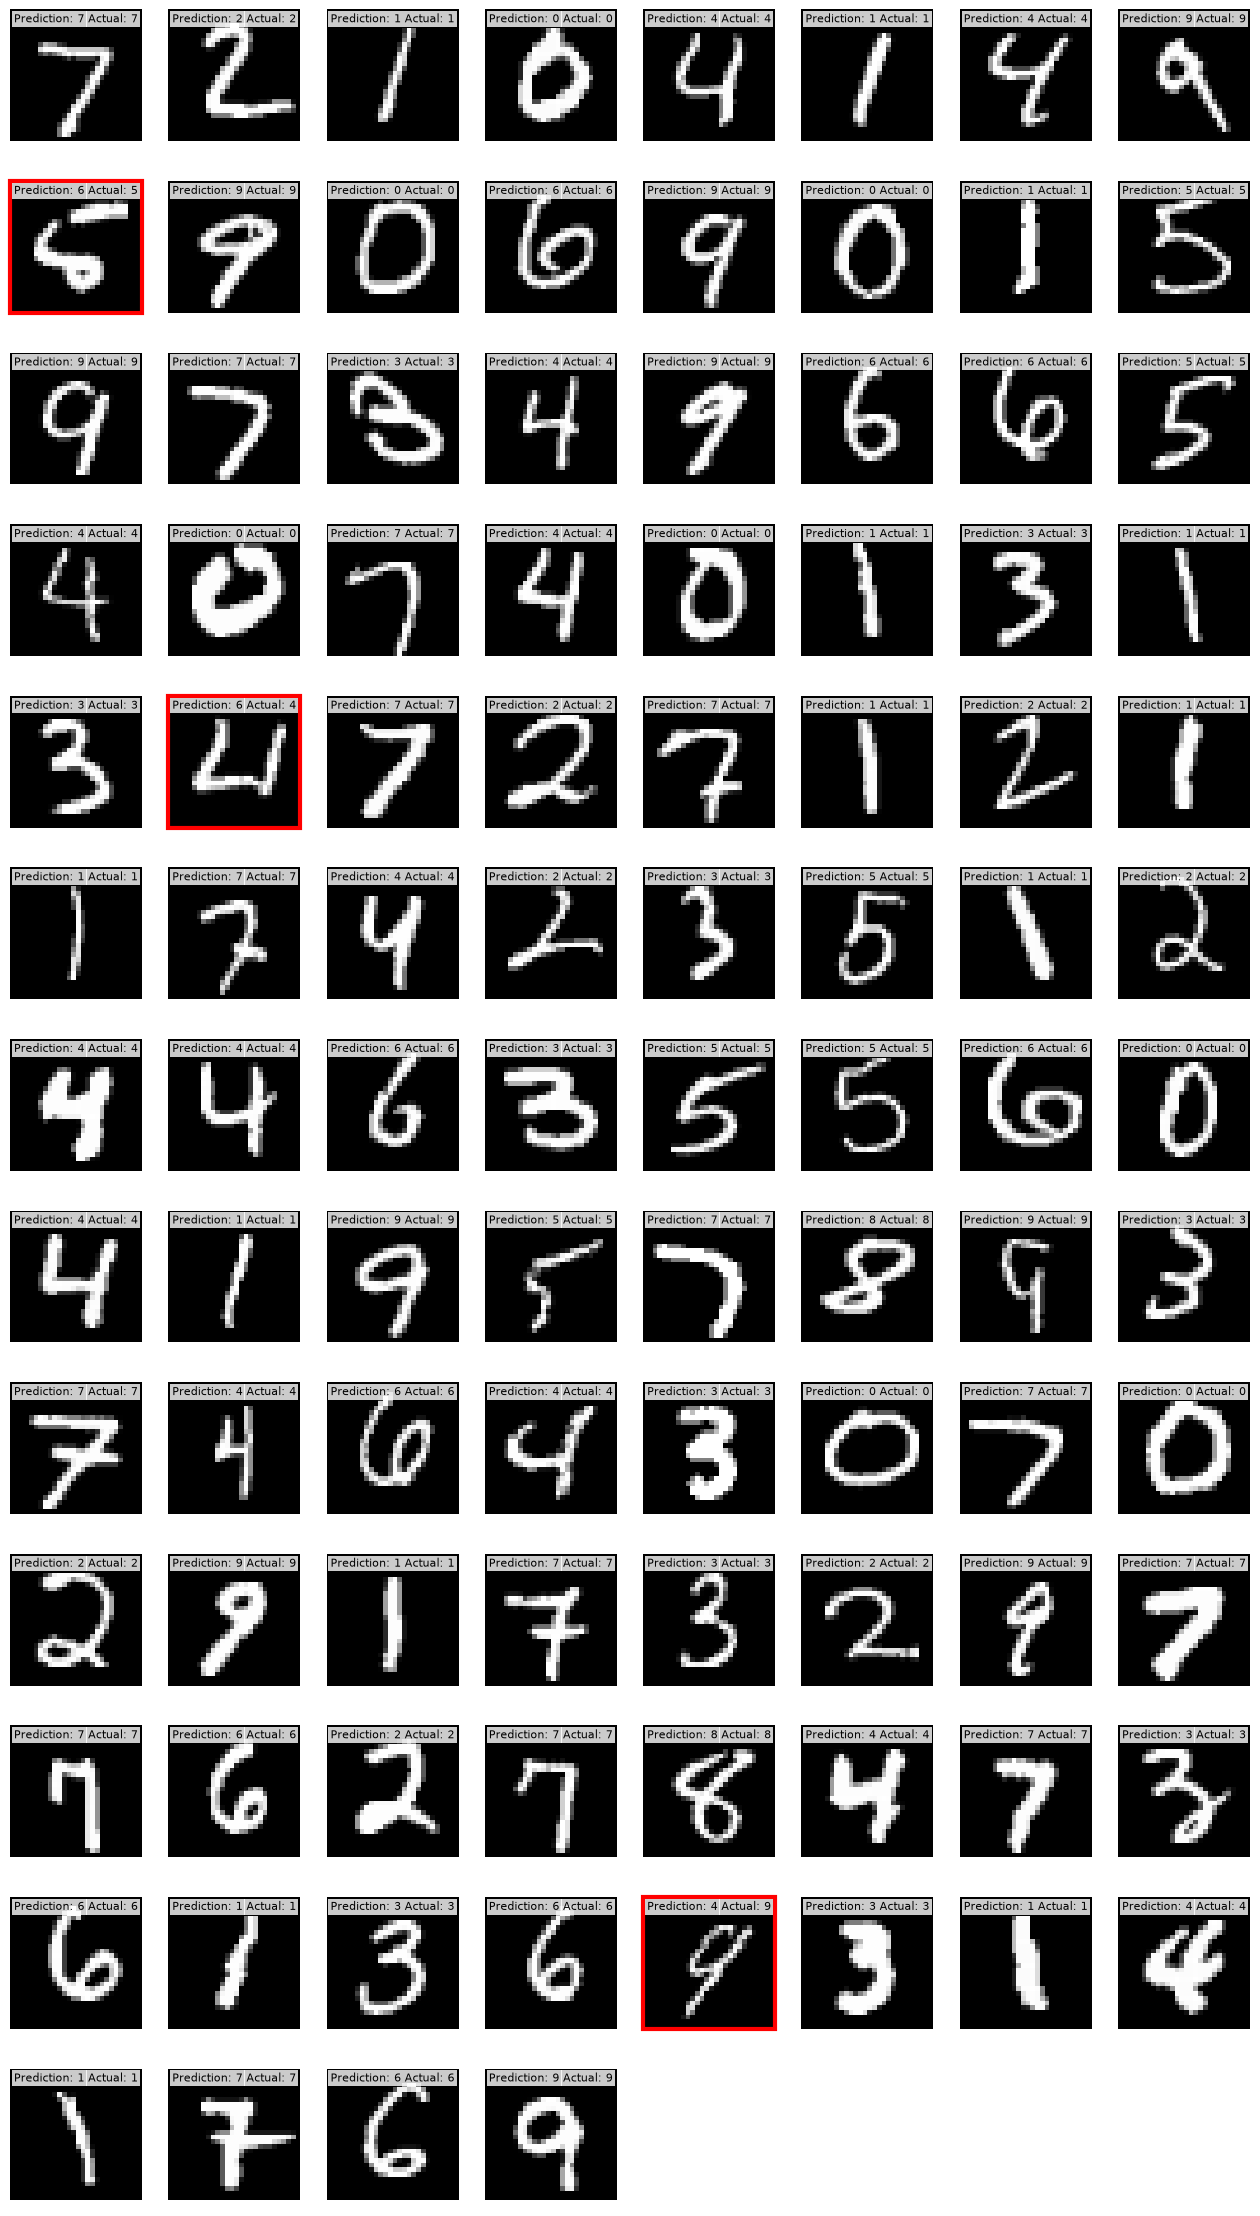

In [13]:
predict(x_test, y_test, 0, 100)
